# code_093 · Centroid and mixture-based clustering

**Book:** section 19.1. A self-contained clustering-and-anomaly laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_19_GUIDE.md), [run evidence](../CHAPTER_19_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_093).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1993;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1993


<a id="objectives"></a>
## Specify what a group should optimize

Generate independent two-component Gaussian descriptor samples, training240/development80/final200. Component0 has mean[-2,0],covariance[[2,1.25],[1.25,1]], component1 mean[2,.5],covariance[[1,-.65],[-.65,1.5]],prior.5. These are abstract operating-descriptor regimes, not measured physical modes. Fix2groups from the declared construction to compare objectives, rather than selecting a method with final labels. Fit training-only StandardScaler, KMeans(n_init20), full and spherical GaussianMixture(n_init5,reg_covar1e-4), and an independently implemented alternating Euclidean medoid fit with twelve starts. The medoid center must be an actual training record; it minimizes a sum of distances within its assigned group, whereas k-means minimizes squared distance to unconstrained centroids. Alternation is a local heuristic, not a global PAM solver. External adjusted Rand indices use generator components only as disclosed diagnostics. Mixture held-out log density is reported separately because the other objectives do not define a normalized density.


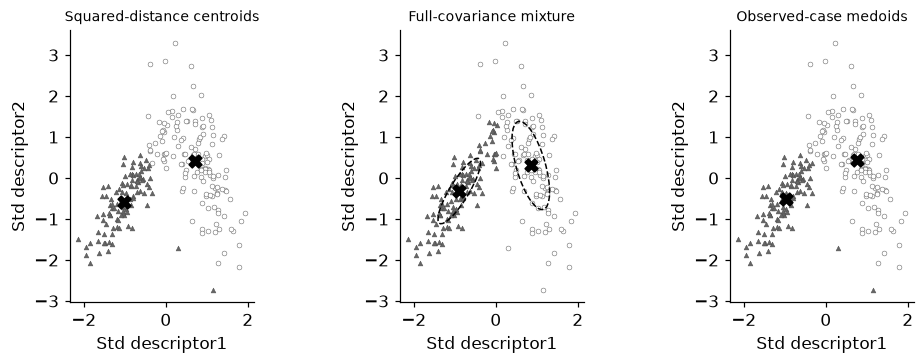

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from scipy.spatial.distance import cdist
from matplotlib.patches import Ellipse
means=np.array([[-2.,0.],[2.,.5]]);covs=np.array([[[2.,1.25],[1.25,1.]],[[1.,-.65],[-.65,1.5]]])
def generate(n):
 label=rng.integers(0,2,n);a=np.empty((n,2))
 for group in [0,1]:a[label==group]=rng.multivariate_normal(means[group],covs[group],size=np.sum(label==group))
 return a,label
X,truth=generate(240);Xd,td=generate(80);Xt,tt=generate(200);sc=StandardScaler().fit(X);S=sc.transform(X);D=sc.transform(Xd);T=sc.transform(Xt);km=KMeans(2,n_init=20,random_state=SEED).fit(S);gm=GaussianMixture(2,covariance_type='full',n_init=5,reg_covar=1e-4,random_state=SEED).fit(S);spherical=GaussianMixture(2,covariance_type='spherical',n_init=5,reg_covar=1e-4,random_state=SEED).fit(S);assert gm.converged_ and spherical.converged_
def medoid_fit(a,starts=12):
 distances=cdist(a,a);best=None
 for _ in range(starts):
  ids=rng.choice(len(a),2,replace=False);history=[]
  for step in range(60):
   labels=np.argmin(distances[:,ids],axis=1);cost=float(distances[np.arange(len(a)),ids[labels]].sum());history.append(cost);updated=ids.copy()
   for group in [0,1]:
    members=np.flatnonzero(labels==group)
    if len(members):updated[group]=members[np.argmin(distances[np.ix_(members,members)].sum(axis=1))]
   assert len(np.unique(updated))==2
   if np.array_equal(updated,ids):break
   ids=updated
  labels=np.argmin(distances[:,ids],axis=1);cost=float(distances[np.arange(len(a)),ids[labels]].sum());assert np.all(np.diff(history)<=1e-9)
  if best is None or cost<best[0]:best=(cost,ids.copy(),history)
 return best
cost,medoid_ids,history=medoid_fit(S);medoid_labels=np.argmin(cdist(S,S[medoid_ids]),axis=1);medoid_final=np.argmin(cdist(T,S[medoid_ids]),axis=1);assert np.all(medoid_ids>=0) and np.all(medoid_ids<len(S));np.testing.assert_allclose(S[medoid_ids],sc.transform(X[medoid_ids]));responsibility=gm.predict_proba(T);np.testing.assert_allclose(responsibility.sum(axis=1),1,atol=1e-12)
rows=[]
for name,labels,final_labels in [('KMeans',km.labels_,km.predict(T)),('Medoids',medoid_labels,medoid_final),('Full mixture',gm.predict(S),gm.predict(T)),('Spherical mixture',spherical.predict(S),spherical.predict(T))]:rows.append({'model':name,'training_component_ARI':float(adjusted_rand_score(truth,labels)),'final_component_ARI':float(adjusted_rand_score(tt,final_labels))})
RESULTS['roles']={'training':240,'development_diagnostic':80,'final':200,'component_count_fixed':2};RESULTS['objectives']={'kmeans_training_squared_distance_sum':float(km.inertia_),'medoid_training_distance_sum':cost,'medoid_training_record_ids':medoid_ids.tolist(),'medoid_starts':12,'selected_medoid_cost_history':history,'comparisons':rows};RESULTS['mixture_densities']={'full_development_mean_log_density':float(gm.score(D)),'spherical_development_mean_log_density':float(spherical.score(D)),'full_final_mean_log_density':float(gm.score(T)),'spherical_final_mean_log_density':float(spherical.score(T)),'density_coordinates':'training-standardized descriptors','final_mean_max_responsibility':float(responsibility.max(axis=1).mean()),'final_fraction_max_responsibility_below_08':float(np.mean(responsibility.max(axis=1)<.8))}
fig,axes=plt.subplots(1,3,figsize=(9,3.2));label_sets=[km.labels_,gm.predict(S),medoid_labels];centers=[km.cluster_centers_,gm.means_,S[medoid_ids]]
for ax,labels,centers_now,name in zip(axes,label_sets,centers,['Squared-distance centroids','Full-covariance mixture','Observed-case medoids']):
 for group,marker,face in [(0,'o','white'),(1,'^','.4')]:
  mask=labels==group;ax.scatter(S[mask,0],S[mask,1],s=10,marker=marker,facecolors=face,edgecolors='.3',linewidths=.3)
 ax.scatter(*centers_now.T,marker='X',s=70,color='black');ax.set(title=name,xlabel='Std descriptor1',ylabel='Std descriptor2',aspect='equal')
for mean,cov in zip(gm.means_,gm.covariances_):
 val,vec=np.linalg.eigh(cov);angle=np.degrees(np.arctan2(vec[1,1],vec[0,1]));axes[1].add_patch(Ellipse(mean,2*np.sqrt(val[1]),2*np.sqrt(val[0]),angle=angle,fill=False,edgecolor='black',ls='--'))
plt.show()


<a id="sensitivity"></a>
## Units and initialization affect the specified objective

Run twelve one-start random initializations of k-means on the same standardized training matrix and retain inertia and partition agreement. Separately multiply descriptor1 by1000 before naive k-means, then fit a training-only standardizer in those storage units. Consistent scaling should recover the standardized partition, up to arbitrary label permutation; the raw stored-number objective can differ. Full-mixture responsibilities describe component assignment conditional on the fitted mixture. They are not automatically probabilities of a verified operating regime or of fault. The plotted ellipses are one-covariance contours, not confidence intervals for estimated means.


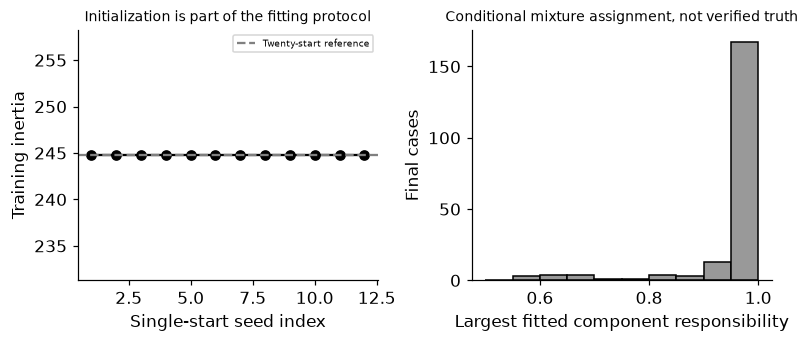

In [3]:
init=[]
for seed in range(SEED,SEED+12):
 fit=KMeans(2,init='random',n_init=1,random_state=seed).fit(S);init.append({'seed':seed,'inertia':float(fit.inertia_),'ARI_with_twenty_start_partition':float(adjusted_rand_score(km.labels_,fit.labels_))})
stored=X*np.array([1000.,1]);raw=KMeans(2,n_init=20,random_state=SEED).fit(stored);unit_sc=StandardScaler().fit(stored);converted=KMeans(2,n_init=20,random_state=SEED).fit(unit_sc.transform(stored));np.testing.assert_allclose(unit_sc.transform(stored),S,atol=1e-12);assert adjusted_rand_score(km.labels_,converted.labels_)==1
RESULTS['sensitivity']={'single_random_start_fits':init,'raw_unit_changed_vs_standardized_partition_ARI':float(adjusted_rand_score(km.labels_,raw.labels_)),'consistently_standardized_unit_conversion_ARI':1.};fig,axes=plt.subplots(1,2,figsize=(7,3));axes[0].plot(range(1,13),[v['inertia'] for v in init],'o-',color='black');axes[0].axhline(km.inertia_,color='.5',ls='--',label='Twenty-start reference');axes[0].set(xlabel='Single-start seed index',ylabel='Training inertia',title='Initialization is part of the fitting protocol');axes[0].legend(fontsize=6);axes[1].hist(responsibility.max(axis=1),bins=np.linspace(.5,1,11),color='.6',edgecolor='black');axes[1].set(xlabel='Largest fitted component responsibility',ylabel='Final cases',title='Conditional mixture assignment, not verified truth');plt.show()


In [4]:
summary={'example_id':'code_093','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['Euclidean centroid versus observed-case medoid objectives', 'full versus spherical mixture assumptions', 'unit scaling and initialization sensitivity', 'model responsibilities versus external regime evidence'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["Euclidean centroid versus observed-case medoid objectives", "full versus spherical mixture assumptions", "unit scaling and initialization sensitivity", "model responsibilities versus external regime evidence"], "elapsed_seconds": 0.455, "example_id": "code_093", "hardware": "Darwin arm64 CPU", "results": {"mixture_densities": {"density_coordinates": "training-standardized descriptors", "final_fraction_max_responsibility_below_08": 0.065, "final_mean_max_responsibility": 0.9641588173668584, "full_development_mean_log_density": -2.1966936170350144, "full_final_mean_log_density": -2.319977579935062, "spherical_development_mean_log_density": -2.6297590836922344, "spherical_final_mean_log_density": -2.772793081792603}, "objectives": {"comparisons": [{"final_component_ARI": 0.36933365019389475, "model": "KMeans", "training_component_ARI": 0.5733161842473165}, {"final_component_ARI": 0.43301946359096755, "model": "Medoids", "training_componen